In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

np.random.seed(42); tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [3]:
num_notes       = 50     # vocabulary size (given)
sequence_length = 30     # notes per melody (given)
num_sequences   = 1000   # number of melodies (given)

data = np.random.randint(0, num_notes, size=(num_sequences, sequence_length))  # (given)

# Q1a) input = all notes except the LAST;  target = all notes except the FIRST
x_train = data[:,:-1]   # TODO (Q1a): data[:, :-1]
y_train = data[:, 1:]   # TODO (Q1a): data[:, 1:]

# Q1b) one-hot encode both to shape (samples, 29, 50)
NUM_CLASSES = 50   # TODO (Q1b): how many distinct notes?
x_train = to_categorical(x_train, num_classes=NUM_CLASSES)
y_train = to_categorical(y_train, num_classes=NUM_CLASSES)

print("x_train:", x_train.shape, " y_train:", y_train.shape)   # expect (1000, 29, 50) each

x_train: (1000, 29, 50)  y_train: (1000, 29, 50)


In [4]:
assert x_train.shape == (1000, 29, 50), "x_train shape should be (1000, 29, 50)"
assert y_train.shape == (1000, 29, 50), "y_train shape should be (1000, 29, 50)"
print("Task 1 looks correct ✔")

Task 1 looks correct ✔


In [5]:
model = models.Sequential()
model.add(layers.Input(shape=(sequence_length-1, num_notes)))        # (29, 50)  (given)

# Q2a) first Bidirectional LSTM: 128 units, return a sequence
model.add(layers.Bidirectional(layers.LSTM(128, return_sequences=True)))  # TODO (Q2a)

# Q2b) second Bidirectional LSTM: same settings
model.add(layers.Bidirectional(layers.LSTM(128, return_sequences=True)))   # TODO (Q2b): another Bidirectional(LSTM(128, return_sequences=True))

# Q2c) TimeDistributed Dense output: one softmax classifier per step
model.add(layers.TimeDistributed(layers.Dense(num_notes, activation='softmax')))  # TODO (Q2c)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 29, 256)        │       183,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 29, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 29, 50)         │        12,850 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 590,386 (2.25 MB)

 Trainable params: 590,386 (2.25 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Q3a) compile for multi-class, one-hot targets
model.compile(optimizer=Adam(learning_rate=0.001),   # TODO (Q3a): 0.001
              loss='categorical_crossentropy',                             # TODO (Q3a): 'categorical_crossentropy'
              metrics=['accuracy'])

# Q3b) train with a 20% validation split
history = model.fit(x_train, y_train,
                    epochs=20,            # TODO (Q3b): 20
                    batch_size=64,        # TODO (Q3b): 64
                    validation_split=0.2)  # TODO (Q3b): 0.2

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 90ms/step - accuracy: 0.1119 - loss: 3.8848 - val_accuracy: 0.1688 - val_loss: 3.8440
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.1490 - loss: 3.7713 - val_accuracy: 0.0978 - val_loss: 3.6595
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.1197 - loss: 3.5263 - val_accuracy: 0.1338 - val_loss: 3.4217
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.1547 - loss: 3.2501 - val_accuracy: 0.1797 - val_loss: 3.1098
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.2050 - loss: 2.8962 - val_accuracy: 0.2322 - val_loss: 2.7330
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.2750 - loss: 2.4836 - val_accuracy: 0.3200 - val_loss: 2.3021
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.3566 - loss: 2.0702 - val_accuracy: 0.3966 - val_loss: 1.9059
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.4465 - loss: 1.6871 - val_accuracy: 0.4914 - 

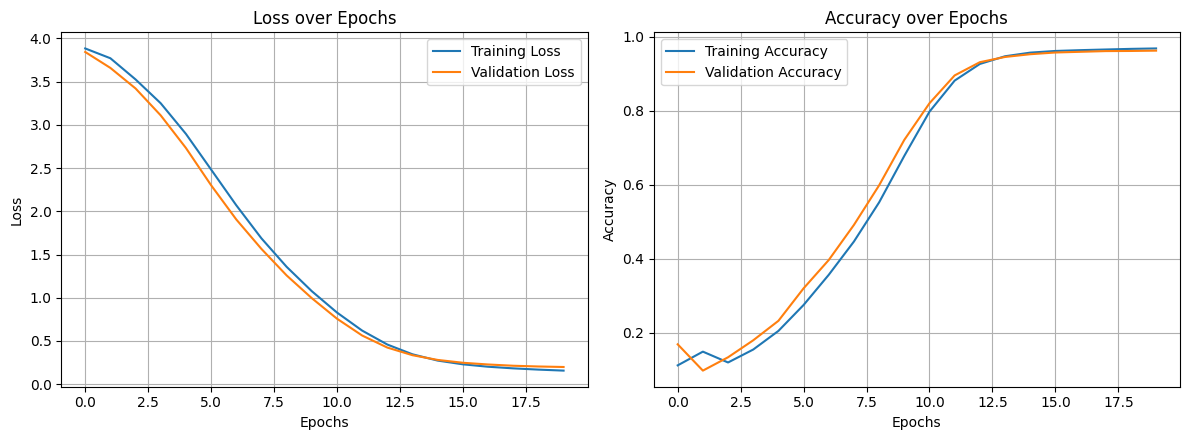

In [13]:
plt.figure(figsize=(12,4.5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'],     label='Training Loss')
plt.plot(history.history['val_loss'],       label='Validation Loss')   # TODO (Q4a): val loss key
plt.title('Loss over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'],       label='Validation Accuracy')  # TODO (Q4b): val acc key
plt.title('Accuracy over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend(); plt.grid()

plt.tight_layout(); plt.show()

In [43]:
def generate_music(model, start_sequence, num_generated_notes=50):
    generated = []
    current_sequence = start_sequence
    for _ in range(num_generated_notes):
        pred = model.predict(current_sequence, verbose=0)      # (1, 29, 50)

        # Q5a) pick the most likely note at the LAST time step
        next_note =np.argmax(pred[:, -1, :], axis=-1)# TODO (Q5a): np.argmax(pred[:, -1, :], axis=-1)
        generated.append(int(next_note[0]))

        # Q5b) slide the window: drop the first step, append the new note (one-hot)
        oh = to_categorical(next_note, num_classes=num_notes).reshape(1, 1, num_notes)
        current_sequence =np.concatenate([current_sequence[:, 1:, :], oh], axis=1)    # TODO (Q5b): np.concatenate([current_sequence[:, 1:, :], oh], axis=1)
    return generated

# seed window (given)
start = np.random.randint(0, num_notes, size=(1, sequence_length-1))
start = to_categorical(start, num_classes=num_notes)

generated_music = generate_music(model, start, num_generated_notes=50)
print("Generated:", generated_music)

Generated: [10, 10, 10, 10, 17, 17, 17, 17, 17, 17, 23, 23, 23, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49, 49]


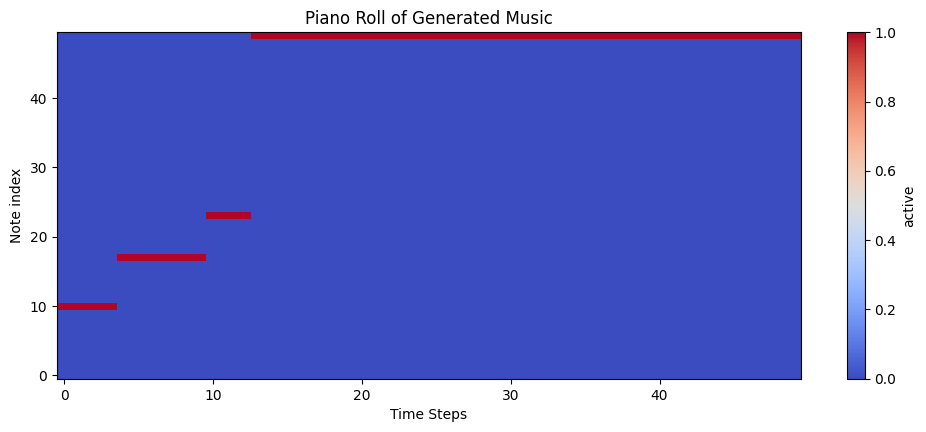

In [44]:
piano_roll = np.zeros((num_notes, len(generated_music)))
for t, note in enumerate(generated_music):
    piano_roll[note, t] = 1   # TODO (Q6): which row is the active note at time t?

plt.figure(figsize=(12,4.5))
plt.imshow(piano_roll, aspect='auto', cmap='coolwarm', origin='lower', interpolation='nearest')
plt.colorbar(label='active'); plt.title('Piano Roll of Generated Music')
plt.xlabel('Time Steps'); plt.ylabel('Note index'); plt.show()

In [39]:
import numpy as np
from IPython.display import Audio
audio = np.concatenate([np.sin(2 * np.pi * (440.0 * (2.0 ** (((48 + n) - 69.0) / 12.0))) * np.linspace(0, 0.25, 2000, False)) for n in generated_music])
Audio(audio, rate=8000)

## Task 7 — Analysis

1. The two Bi-LSTM layers both use `return_sequences=True`. What would break if you set it to
   `False` on the first layer?
2. Why is the first Bi-LSTM's output width **256** when the LSTM has 128 units?
3. What does `TimeDistributed(Dense(50))` do that a plain `Dense(50)` would not?
4. You trained on **random** notes, yet accuracy reaches ~96%. **Explain the mechanism.**
   *(Hint: the target at step t equals the input at step t+1 — which direction of a bidirectional
   layer can already see it?)*
5. Why is a **bidirectional** model a poor choice for *autoregressive generation*, and what two
   changes would make this an honest music generator?

> **Your answers:**
> 1. Setting `return_sequences=False` on the first layer makes it only return the output of the final time step (reducing the tensor dimension from 3D `(batch, steps, features)` to 2D `(batch, features)`). This would break the next Bi-LSTM layer, which expects a 3D sequence as input.
> 2. A bidirectional wrapper contains two independent LSTM layers: one processing the sequence forwards and one processing it backwards. Since Keras concatenates their outputs by default, the resulting width is `128 (forward) + 128 (backward) = 256` units.
> 3. `TimeDistributed(Dense(50))` explicitly applies the same Dense layer (sharing the exact same weights) to each individual time step of the sequence independently. In modern Keras, a plain `Dense(50)` applied to a 3D input behaves the same way, but using `TimeDistributed` formally enforces sequence-to-sequence application.
> 4. Since the bidirectional layer runs in both directions, the backward LSTM processing from right to left (t to 0) can directly read the input at step $t+1$ when predicting the target at step $t$. Because the target $y_t$ is exactly $x_{t+1}$, the backward LSTM simply copies the future inputs, allowing the model to easily achieve ~96% accuracy on completely random noise by 'cheating' through look-ahead.
> 5. A bidirectional model is bad for autoregressive generation because it relies on seeing the future (the backward pass), which does not exist during generation. Two changes to make this an honest music generator would be:
>    * Using a standard **unidirectional (causal) LSTM** or a causal masking mechanism so the model only looks at past inputs.
>    * Training the model on **actual structured musical data** (patterns/melodies) rather than purely random data, so that it learns true sequential relationships.